In [1]:
import os, sys
from pathlib import Path

try:
    base = Path(__vsc_ipynb_file__).resolve().parent  # VS Code sabe dónde está el notebook
except NameError:
    base = Path.cwd()
RAIZ = next(p for p in [base, *base.parents] if (p / "src").is_dir())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
print(RAIZ)


C:\Users\luis.huezo\Documents\Capacitacion\Aprueba+\Aprueba-


In [11]:
import pandas as pd
from src.ingesta import ingesta_dask as i
from src import config

from src.modelos.curva_aprendizaje import (
        dividir_fuera_de_tiempo,linea_base_grado,curva_aprendizaje,resumir
)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score


In [ ]:

print(len(config.VARIABLES_NUMERICAS), len(config.VARIABLES_CATEGORICAS))

28 4


### Procesar los datos con dask

In [ ]:
i.descomprimir
resultado = i.procesar_con_dask()

In [3]:
resultado

{'particiones': 26, 'filas': 1347734, 'segundos': 21.6}

### Lectura con pandas

In [6]:
datapd = pd.read_parquet(config.PARQUET_PRESTAMOS)
datapd.shape, round(datapd.es_malo.mean(),4)

((1347734, 31), 0.1998)

Alrededor de `20%`-ish de defaults

Se realizó una prueba con el tamaño de muestar con 1k que se encuentra en repo, el valor es 0.713 que es valor que se espera vencer al realizar este ejercicio.

Se toman muestras al azar del dataset,las pequeñas se realizan a mayor precuencia, las largas que abarcan porciones mas significativas del dataset. La intención de reducir lo más posible las varianza dispar entre muestras pequeñas pocas veces y una muestra que es porcentaje significativo de la data ejecutada la misma cantidad de veces.

In [ ]:
entrenamiento,prueba = dividir_fuera_de_tiempo(datapd)
print(linea_base_grado(prueba))
resultSmall = curva_aprendizaje(entrenamiento,prueba,[1000 , 10000], repeticiones=15)
resultLarge = curva_aprendizaje(entrenamiento,prueba,[100000, 400000], repeticiones=3)
resultados = pd.concat([resultSmall,resultLarge], ignore_index=True)
resumir(resultados)

{'auc_grado': 0.6698033352220095, 'exactitud_todos_buenos': 0.7817558459203278}


c:\Users\luis.huezo\Documents\Capacitacion\Aprueba+\Aprueba-\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\luis.huezo\Documents\Capacitacion\Aprueba+\Aprueba-\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\luis.huezo\AppData\Roaming\uv\python\cpython-3.11-windows-x86_64-none\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\luis.huezo\AppData\Roaming\uv\python\cpython-3.11-windows-x86_64-none\Lib\subprocess.py", line 1

,n,modelo,auc_media,auc_desv,exactitud_media,exactitud_desv
0,1000,boosting,0.623619,0.007998,0.778041,0.003368
1,1000,logistica,0.649481,0.010021,0.778638,0.002405
2,1000,mlp,0.556726,0.059903,0.779941,0.002076
3,10000,boosting,0.667862,0.002957,0.781269,0.000802
4,10000,logistica,0.671133,0.003573,0.781829,0.000252
5,10000,mlp,0.647370,0.032413,0.781548,0.000959
6,100000,boosting,0.684512,0.000533,0.782823,0.000188
7,100000,logistica,0.673708,0.001492,0.782035,0.000204
8,100000,mlp,0.679329,0.001911,0.781140,0.000380
9,400000,boosting,0.688213,0.000476,0.782808,0.000118


In [9]:
print(linea_base_grado(prueba))

{'auc_grado': 0.6698033352220095, 'exactitud_todos_buenos': 0.7817558459203278}


Se aprecia virtualmente no diferencia entre los 3 modelos probados, aunque Boosting parece converger mas rapido hacias el valor que parece ser el limite. MLP es bastante similar y escala con la cantidad de muestras. Pero no se espera mayor mejora aún entregando un mayor numero de muestras y pares a comparar.

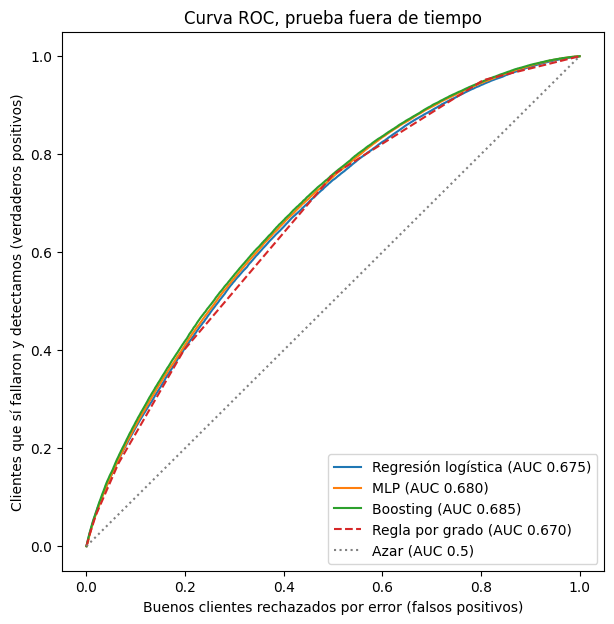

Regresión logística  detecta 40.5% de los castigados
MLP                  detecta 41.1% de los castigados
Boosting             detecta 41.9% de los castigados
Regla por grado      detecta 40.3% de los castigados


In [ ]:
COLS = config.VARIABLES_NUMERICAS + config.VARIABLES_CATEGORICAS
muestra = entrenamiento.sample(n=100_000, random_state=42)
X_ent, y_ent = muestra[COLS], muestra[config.VARIABLE_OBJETIVO]
X_pru, y_pru = prueba[COLS], prueba[config.VARIABLE_OBJETIVO]

modelos = {
    "Regresión logística": construir_regresion_logistica(),
    "MLP": construir_mlp(),
    "Boosting": construir_gradient_boosting(),
}

fig, ax = plt.subplots(figsize=(7, 7))
curvas = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_ent, y_ent)
    p = modelo.predict_proba(X_pru)[:, 1]
    fpr, tpr, _ = roc_curve(y_pru, p)
    curvas[nombre] = (fpr, tpr)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y_pru, p):.3f})")

grado = prueba["grade"].map("ABCDEFG".index)
fpr, tpr, _ = roc_curve(y_pru, grado)
curvas["Regla por grado"] = (fpr, tpr)
ax.plot(fpr, tpr, "--", label=f"Regla por grado (AUC {roc_auc_score(y_pru, grado):.3f})")
ax.plot([0, 1], [0, 1], ":", color="gray", label="Azar (AUC 0.5)")

ax.set_xlabel("Buenos clientes rechazados por error (falsos positivos)")
ax.set_ylabel("Clientes que sí fallaron y detectamos (verdaderos positivos)")
ax.set_title("Curva ROC, prueba fuera de tiempo")
ax.legend(loc="lower right")
plt.show()

# Lectura concreta: si aceptamos rechazar por error al 20 % de los buenos,
# ¿qué porcentaje de los que fallarán detectamos?
for nombre, (fpr, tpr) in curvas.items():
    print(f"{nombre:20s} detecta {np.interp(0.20, fpr, tpr):.1%} de los castigados")


### Añadir features adicionales al parquet

Se realizan cambios en los archivos del repositorio, en especifico al agregar mas features a evaluar de forma que los modelos tengan mas datos que evaluar. Se evitan aquellos que puedan llevar a data leakage como el score FICO. Datos como meses desde ultimo default o el porcentaje sobre ingreso que este prestamo representa son añadidos al parquet (Valor calculado)

Se ajustan los modelos

Se ejecuta de nuevo la ingesta desde root del proyecto:

```python
python -c "from src.ingesta import ingesta_dask as i; print(i.procesar_con_dask())"
python -c "from src.ingesta import ingesta_dask as i; i.guardar_muestra()"
python -m pytest
```

In [ ]:
#Guardamos una copia con los resultados
resumir(resultados).to_csv(config.REPORTES / "curva_15_variables.csv", index=False)

### Pruebas con features adicionales

Se carga nuevamente el parquet con los features adicionales, se recarga el Kernel, se evita ejecutar todas las celdas anteriores y se guarda una copia manual de los resultados anteriores.

In [12]:
antes = pd.DataFrame(
    [
        (1000, "boosting", 0.623619), (1000, "logistica", 0.649481), (1000, "mlp", 0.556726),
        (10000, "boosting", 0.667862), (10000, "logistica", 0.671133), (10000, "mlp", 0.647370),
        (100000, "boosting", 0.684512), (100000, "logistica", 0.673708), (100000, "mlp", 0.679329),
        (400000, "boosting", 0.688213), (400000, "logistica", 0.673770), (400000, "mlp", 0.684680),
    ],
    columns=["n", "modelo", "auc_antes"],
)

In [13]:
datapd2 = pd.read_parquet(config.PARQUET_PRESTAMOS)
datapd2.shape, round(datapd2.es_malo.mean(),4)

((1347734, 48), 0.1998)

In [14]:
entrenamiento2,prueba2 = dividir_fuera_de_tiempo(datapd2)
print(linea_base_grado(prueba2))
resultSmall2 = curva_aprendizaje(entrenamiento2,prueba2,[10000], repeticiones=25)
resultLarge2 = curva_aprendizaje(entrenamiento2,prueba2,[400000], repeticiones=3)
resultados2 = pd.concat([resultSmall2,resultLarge2], ignore_index=True)
resumir(resultados2)

{'auc_grado': 0.6698033352220095, 'exactitud_todos_buenos': 0.7817558459203278}


c:\Users\luis.huezo\Documents\Capacitacion\Aprueba+\Aprueba-\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\luis.huezo\Documents\Capacitacion\Aprueba+\Aprueba-\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\luis.huezo\AppData\Roaming\uv\python\cpython-3.11-windows-x86_64-none\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\luis.huezo\AppData\Roaming\uv\python\cpython-3.11-windows-x86_64-none\Lib\subprocess.py", line 1

,n,modelo,auc_media,auc_desv,exactitud_media,exactitud_desv
0,10000,boosting,0.675401,0.003820,0.781478,0.000866
1,10000,logistica,0.682987,0.003614,0.779531,0.001813
2,10000,mlp,0.670364,0.013077,0.778434,0.003613
3,400000,boosting,0.700825,0.001084,0.784210,0.000270
4,400000,logistica,0.689244,0.000957,0.781581,0.000565
5,400000,mlp,0.698824,0.001011,0.783674,0.000538


In [15]:
print(linea_base_grado(prueba2))

{'auc_grado': 0.6698033352220095, 'exactitud_todos_buenos': 0.7817558459203278}


In [16]:
despues = resumir(resultados2)[["n", "modelo", "auc_media"]].rename(columns={"auc_media": "auc_despues"})
comparacion = antes.merge(despues, on=["n", "modelo"])
comparacion["cambio"] = comparacion["auc_despues"] - comparacion["auc_antes"]
comparacion.sort_values(["n", "modelo"])

,n,modelo,auc_antes,auc_despues,cambio
0,10000,boosting,0.667862,0.675401,0.007539
1,10000,logistica,0.671133,0.682987,0.011854
2,10000,mlp,0.647370,0.670364,0.022994
3,400000,boosting,0.688213,0.700825,0.012612
4,400000,logistica,0.673770,0.689244,0.015474
5,400000,mlp,0.684680,0.698824,0.014144


Se aprecia un cambio menor pero medible. En especial al utilizar boosting. Pero dados los acuerdos tomados para el proyecto. Se procede a utilizar MLP como se acordó, pero se nota que boosting da marginalmente mejores resultados en la escala actual de pruebas que se realizan.

### Se intenta realizar un poco de tuning 

In [19]:
import time
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import ParameterSampler

from src import config
from src.modelos.curva_aprendizaje import dividir_fuera_de_tiempo
from src.modelos.pipelines import construir_gradient_boosting, construir_mlp

DATOS = datapd2          # <- cambia al nombre de tu DataFrame de 48 columnas
OBJ = config.VARIABLE_OBJETIVO
COLS = config.VARIABLES_NUMERICAS + config.VARIABLES_CATEGORICAS
print(len(config.VARIABLES_NUMERICAS), len(config.VARIABLES_CATEGORICAS))  # debe ser 28 4

ent, pru = dividir_fuera_de_tiempo(DATOS)                 # mismo corte que antes
ent_tun, val = dividir_fuera_de_tiempo(ent, 0.2)          # validación DENTRO del entrenamiento
ent_tun = ent_tun.sample(n=200_000, random_state=42)      # la prueba NO se toca al ajustar


def buscar(constructor, espacio, n_iter, semilla=42):
    filas = []
    for params in ParameterSampler(espacio, n_iter=n_iter, random_state=semilla):
        inicio = time.perf_counter()
        modelo = constructor(semilla).set_params(**params)
        modelo.fit(ent_tun[COLS], ent_tun[OBJ])
        auc = roc_auc_score(val[OBJ], modelo.predict_proba(val[COLS])[:, 1])
        filas.append({**params, "auc_validacion": auc,
                      "segundos": round(time.perf_counter() - inicio)})
    return filas


28 4


### Tune para Boosting

In [20]:
espacio_boosting = {
    "modelo__learning_rate": [0.03, 0.05, 0.1],
    "modelo__max_leaf_nodes": [15, 31, 63],
    "modelo__min_samples_leaf": [20, 100, 500],
    "modelo__l2_regularization": [0.0, 1.0, 10.0],
    "modelo__max_iter": [300, 600],
}
tuning_boosting = buscar(construir_gradient_boosting, espacio_boosting, n_iter=12)
pd.DataFrame(tuning_boosting).sort_values("auc_validacion", ascending=False)


,modelo__min_samples_leaf,modelo__max_leaf_nodes,modelo__max_iter,modelo__learning_rate,modelo__l2_regularization,auc_validacion,segundos
2,500,31,300,0.05,10.0,0.715519,11
6,500,15,600,0.10,1.0,0.715429,8
5,500,15,600,0.05,0.0,0.715400,11
9,20,15,300,0.10,10.0,0.714750,7
0,500,31,600,0.10,10.0,0.714673,8
8,100,15,600,0.10,1.0,0.714584,6
11,20,31,600,0.05,1.0,0.714143,9
4,100,31,300,0.10,1.0,0.714113,7
10,100,15,300,0.05,0.0,0.713579,10
1,100,15,300,0.03,10.0,0.713043,13


### Tuning para MLP

Se espera un tiempo de ejecución extendido

In [21]:
espacio_mlp = {
    "modelo__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32), (256, 128)],
    "modelo__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
    "modelo__learning_rate_init": [3e-4, 1e-3],
    "modelo__batch_size": [256, 512, 1024],
}
tuning_mlp = buscar(construir_mlp, espacio_mlp, n_iter=8)
pd.DataFrame(tuning_mlp).sort_values("auc_validacion", ascending=False)


,modelo__learning_rate_init,modelo__hidden_layer_sizes,modelo__batch_size,modelo__alpha,auc_validacion,segundos
2,0.0010,"(64, 32)",256,0.100,0.714487,55
1,0.0010,"(128, 64, 32)",256,0.100,0.713919,68
7,0.0003,"(128, 64)",1024,0.001,0.713173,39
3,0.0003,"(256, 128)",1024,0.100,0.712218,85
0,0.0003,"(64, 32)",512,0.100,0.711121,18
4,0.0010,"(64, 32)",512,0.001,0.710937,19
5,0.0010,"(256, 128)",256,0.100,0.710214,39
6,0.0010,"(128, 64, 32)",1024,0.010,0.708073,34


### Probar los modelos entre ellos

In [22]:
def evaluar(constructor, params, n=400_000, repeticiones=3):
    aucs = []
    for i in range(repeticiones):
        muestra = ent.sample(n=n, random_state=42 + i)
        modelo = constructor(42 + i).set_params(**params)
        modelo.fit(muestra[COLS], muestra[OBJ])
        aucs.append(roc_auc_score(pru[OBJ], modelo.predict_proba(pru[COLS])[:, 1]))
    return np.mean(aucs), np.std(aucs, ddof=1)


def mejores_params(filas, espacio):
    mejor = max(filas, key=lambda f: f["auc_validacion"])
    return {k: mejor[k] for k in espacio}


p_boost = mejores_params(tuning_boosting, espacio_boosting)
p_mlp = mejores_params(tuning_mlp, espacio_mlp)
print(p_boost); print(p_mlp)

media_b, desv_b = evaluar(construir_gradient_boosting, p_boost)
media_m, desv_m = evaluar(construir_mlp, p_mlp)

pd.DataFrame(
    {
        "modelo": ["boosting", "mlp"],
        "auc_sin_ajustar": [0.700825, 0.698824],     # resultados anteriores
        "auc_ajustado": [media_b, media_m],
        "desv": [desv_b, desv_m],
    }
).assign(cambio=lambda t: t["auc_ajustado"] - t["auc_sin_ajustar"])


{'modelo__learning_rate': 0.05, 'modelo__max_leaf_nodes': 31, 'modelo__min_samples_leaf': 500, 'modelo__l2_regularization': 10.0, 'modelo__max_iter': 300}
{'modelo__hidden_layer_sizes': (64, 32), 'modelo__alpha': 0.1, 'modelo__learning_rate_init': 0.001, 'modelo__batch_size': 256}


,modelo,auc_sin_ajustar,auc_ajustado,desv,cambio
0,boosting,0.700825,0.702308,0.000424,0.001483
1,mlp,0.698824,0.696062,0.003017,-0.002762


Se aprecia un empeoramiento en el modelo. Menor. Se decide no tratar de optimizar el modelo mas allá de lo que se ha tomado. Se toma el MLP en la configuración inicial.

AUC en prueba: 0.6996 | épocas entrenadas: 17


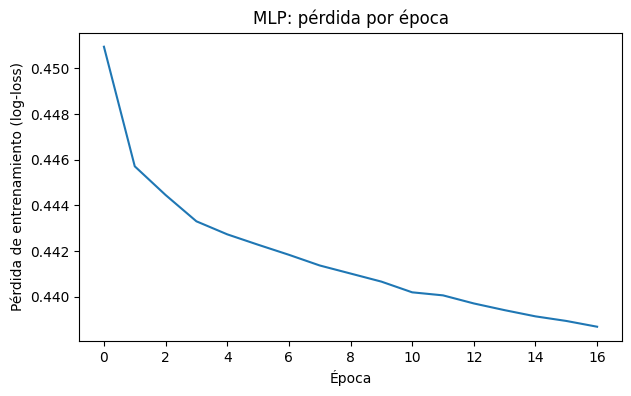

Guardado en C:\Users\luis.huezo\Documents\Capacitacion\Aprueba+\Aprueba-\models\modelo_aprueba_mlp.joblib


In [23]:
import json, platform
import joblib
import sklearn
import matplotlib.pyplot as plt
from datetime import date

mlp = construir_mlp()                                 
muestra = ent.sample(n=400_000, random_state=42)
mlp.fit(muestra[COLS], muestra[OBJ])

red = mlp.named_steps["modelo"]
auc_prueba = roc_auc_score(pru[OBJ], mlp.predict_proba(pru[COLS])[:, 1])
print(f"AUC en prueba: {auc_prueba:.4f} | épocas entrenadas: {red.n_iter_}")

# Curva de pérdida por época
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(red.loss_curve_)
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida de entrenamiento (log-loss)")
ax.set_title("MLP: pérdida por época")
plt.show()

# Guardar modelo y ficha
config.MODELOS.mkdir(exist_ok=True)
joblib.dump(mlp, config.MODELOS / "modelo_aprueba_mlp.joblib")
claves = ["hidden_layer_sizes", "alpha", "early_stopping", "validation_fraction",
          "n_iter_no_change", "max_iter", "learning_rate_init", "batch_size"]
ficha = {
    "modelo": "MLPClassifier",
    "fecha_entrenamiento": date.today().isoformat(),
    "hiperparametros": {k: red.get_params()[k] for k in claves},
    "epocas_entrenadas": red.n_iter_,
    "variables_numericas": config.VARIABLES_NUMERICAS,
    "variables_categoricas": config.VARIABLES_CATEGORICAS,
    "filas_entrenamiento": len(muestra),
    "prueba": {"filas": len(pru), "cosecha_min": pru["cosecha"].min(), "cosecha_max": pru["cosecha"].max()},
    "auc_prueba": auc_prueba,
    "version_scikit_learn": sklearn.__version__,
    "version_python": platform.python_version(),
}
(config.MODELOS / "modelo_aprueba_mlp.json").write_text(
    json.dumps(ficha, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)
print("Guardado en", config.MODELOS / "modelo_aprueba_mlp.joblib")


In [24]:
import numpy as np
cargado = joblib.load(config.MODELOS / "modelo_aprueba_mlp.joblib")
m = pru[COLS].head(1000)
print(np.allclose(cargado.predict_proba(m), mlp.predict_proba(m)))   # debe ser True


True
